## 0. Setup e caricamento dei dati

Carichiamo gli insiemi codificati già pronti in `data/encoded/`:
- `train_enc` (~3 M flow): il modello impara qui;
- `tune_enc` (~1 M flow, ultimo 10% del train): early stopping e scelta degli iperparametri.

La validation **non** viene caricata: servirà solo alla fine, con la configurazione già scelta.

`start_rtt` viene trasformato come in B2: log, poi standardizzazione con media e deviazione
stimate solo su `train_enc`.

Prepariamo anche:
- un **sottoinsieme fisso di 500.000 flow del train**, per misurare la MAE sul train a fine
  epoca sempre sugli stessi flow (serve per confrontare train e tune);
- il **riferimento B0** sul tune: la mediana del train, prevista per ogni flow. Ogni MLP
  deve fare meglio di questo numero.

In questo kernel non si importa LightGBM (conflitto con torch su Mac).

In [ ]:
import copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from flowtok import data, evaluation, paths
from flowtok.models import b2_linear      # riusiamo load, rtt_transform, apply_rtt

SEED = 0
rng = np.random.default_rng(SEED)         # generatore casuale riproducibile

# --- informazioni sulle colonne -------------------------------------------
meta = data.load_meta()
id_columns = meta["id_columns"]           # i nomi delle 13 colonne id_*, nell'ordine di X
n_codes = data.n_codes_per_column(meta)   # righe della tabella di ogni colonna

print(pd.DataFrame({"column": id_columns, "n_codes": n_codes}).to_string(index=False))
print("total codes:", sum(n_codes))       # deve tornare 1.731, come i coefficienti di B2

# --- dati ------------------------------------------------------------------
_, X_tr, rtt_tr, y_tr = b2_linear.load("train_enc", meta)
_, X_tu, rtt_tu, y_tu = b2_linear.load("tune_enc", meta)

mu, sigma = b2_linear.rtt_transform(rtt_tr)          # stimati solo su train_enc
x_tr = b2_linear.apply_rtt(rtt_tr, mu, sigma)
x_tu = b2_linear.apply_rtt(rtt_tu, mu, sigma)

print(f"train: {X_tr.shape}, tune: {X_tu.shape}")
print(f"log(start_rtt): mu = {mu:.3f}, sigma = {sigma:.3f}")
print(f"x_rtt train: mean = {x_tr.mean():.3f}, std = {x_tr.std():.3f}")   # ~0 e ~1

# --- sottoinsieme fisso del train per misurare la MAE sul train ------------
idx_check = rng.choice(len(y_tr), size=500_000, replace=False) # è costante 

# --- riferimento B0 sul tune -----------------------------------------------
median_tr = float(np.median(y_tr))
mae_b0_tune = float(np.abs(median_tr - y_tu).mean())
print(f"B0 median = {median_tr:.3f}  ->  tune MAE = {mae_b0_tune:.4f}")

                  column  n_codes
           id_ip_version        6
           id_experiment       10
              id_exp_act       33
          id_application       60
             id_hostname      690
          id_server_site       87
          id_client_site       87
            id_server_L2      344
            id_client_L2      344
         id_service_port       50
     id_client_port_band        8
          id_orientation        6
id_orientation_ambiguous        6
total codes: 1731
train: (3000316, 13), tune: (1000351, 13)
log(start_rtt): mu = 2.823, sigma = 1.653
x_rtt train: mean = 0.000, std = 1.000
B0 median = 4.405  ->  tune MAE = 3.2094


### Funzione per le curve di apprendimento

`plot_history(history)` disegna la MAE epoca per epoca: train (sottoinsieme fisso) e tune,
se presente. Opzionale: una linea orizzontale di riferimento (es. B0 sul tune).
Le due curve insieme servono a diagnosticare underfitting e overfitting.

In [13]:
import matplotlib.pyplot as plt

CURVES = {"train_mae": ("train", "#257de0"), "tune_mae": ("tune", "#f47230")}

def plot_history(history, title="", reference=None, ref_label="B0", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4))
    show_markers = len(history) <= 30                 # niente pallini con 200 epoche
    for col, (label, color) in CURVES.items():
        if col in history:
            ax.plot(history["epoch"], history[col], color=color, lw=2, label=label,
                    marker="o" if show_markers else None, ms=5)
    if reference is not None:
        ax.axhline(reference, color="#999999", lw=1, ls="--",
                   label=f"{ref_label} ({reference:.3f})")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MAE (ms)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
    ax.set_axisbelow(True)                            # griglia dietro alle curve
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)            # toglie i bordi superfluo
    ax.legend(frameon=False)
    return ax

## 1. Il modello MLP

Per ogni flow:
1. ognuno dei 13 codici sceglie una riga (un vettore di lunghezza `d`) nella tabella della sua
   colonna (`nn.Embedding`). Le tabelle sono separate per server e client, come in B2;
2. i 13 vettori vengono affiancati e si aggiunge `x_rtt`: un vettore di lunghezza 13·d + 1;
3. il vettore attraversa gli strati nascosti, ciascuno `Linear` + `ReLU` (con dropout opzionale);
4. uno strato finale `Linear(…, 1)` produce la previsione di `delta_rtt`.

Larghezze e numero di strati si passano come lista `hidden`, es. `[256, 128]`. Così la stessa
classe serve per tutte le configurazioni della griglia.

Lo strato finale parte con pesi nulli e intercetta uguale alla mediana del train: il modello
non addestrato prevede esattamente come B0 (MAE 3,209 sul tune), come in B2.

Sotto, un controllo: numero di parametri e una previsione su 5 flow.

Opzione `table_names`: una lista con il nome della tabella usata da ogni colonna.
Colonne con lo stesso nome usano la **stessa** tabella. Due scelte predefinite:
- `SEPARATE`: una tabella per colonna (come in B2), 13 tabelle;
- `SHARED`: siti e reti L2 condivisi tra server e client (come i vocabolari), 11 tabelle.
Il ruolo resta distinguibile perché le due colonne entrano nel primo strato in posizioni diverse,
quindi con pesi diversi.

In [62]:
# nome della tabella per ogni colonna, nell'ordine di id_columns
vocab = data.load_vocabularies()
column_vocab = {c: name for name, cols in vocab["columns"].items() for c in cols}

SEPARATE = [c.removeprefix("id_") for c in id_columns]                 # 13 nomi diversi
SHARED   = [column_vocab[c.removeprefix("id_")] for c in id_columns]   # "site" e "L2" ripetuti
print("shared:", SHARED)


class MLP(nn.Module):
    def __init__(self, n_codes, d, hidden, initial_output, table_names, dropout=0.0, norm=None, init=None):
        super().__init__()
        size = dict(zip(table_names, n_codes))
        self.table_names = table_names
        self.emb = nn.ModuleDict({k: nn.Embedding(size[k], d) for k in dict.fromkeys(table_names)})

        layers = []
        width_in = len(table_names) * d + 1
        for width in hidden:
            # con la batch norm il bias della Linear è inutile: lo sostituisce beta
            layers.append(nn.Linear(width_in, width, bias=(norm != "batch")))
            if norm == "batch":
                layers.append(nn.BatchNorm1d(width))   # normalizza sul batch, poi gamma*h + beta
            elif norm == "layer":
                layers.append(nn.LayerNorm(width))     # normalizza sui neuroni dello stesso flow
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            width_in = width
        self.body = nn.Sequential(*layers)
        if init == "he":                              # sigma = sqrt(2 / n_in), bias a zero
            for layer in self.body:
                if isinstance(layer, nn.Linear):
                    nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)

        self.out = nn.Linear(width_in, 1)
        nn.init.zeros_(self.out.weight)
        nn.init.constant_(self.out.bias, initial_output)

    def forward(self, x_cat, x_rtt):
        parts = [self.emb[k](x_cat[:, j]) for j, k in enumerate(self.table_names)]
        h = torch.cat(parts + [x_rtt.unsqueeze(1)], dim=1)
        h = self.body(h)
        return self.out(h).squeeze(1)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


# --- controllo: le due versioni --------------------------------------------
for name, tables in [("separate", SEPARATE), ("shared", SHARED)]:
    torch.manual_seed(SEED)
    model = MLP(n_codes, d=16, hidden=[256, 128], initial_output=median_tr, table_names=tables)
    with torch.no_grad():
        pred = model(torch.from_numpy(X_tr[:5]).long(), torch.from_numpy(x_tr[:5]))
    print(f"{name:9s}: {len(model.emb)} tables, {n_params(model):,} parameters, pred = {pred.numpy()}")
    print(f"\n{model}")

shared: ['ip_version', 'experiment', 'exp_act', 'application', 'hostname', 'site', 'site', 'L2', 'L2', 'service_port', 'client_port_band', 'orientation', 'orientation_ambiguous']
separate : 13 tables, 114,481 parameters, pred = [4.405 4.405 4.405 4.405 4.405]

MLP(
  (emb): ModuleDict(
    (ip_version): Embedding(6, 16)
    (experiment): Embedding(10, 16)
    (exp_act): Embedding(33, 16)
    (application): Embedding(60, 16)
    (hostname): Embedding(690, 16)
    (server_site): Embedding(87, 16)
    (client_site): Embedding(87, 16)
    (server_L2): Embedding(344, 16)
    (client_L2): Embedding(344, 16)
    (service_port): Embedding(50, 16)
    (client_port_band): Embedding(8, 16)
    (orientation): Embedding(6, 16)
    (orientation_ambiguous): Embedding(6, 16)
  )
  (body): Sequential(
    (0): Linear(in_features=209, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
  )
  (out): Linear(in_features=128, out_feature

## 2. Funzione di training

`fit_mlp(cfg, ...)` addestra un MLP descritto dal dizionario `cfg`:
`d`, `hidden`, `tables`, `lr`, `batch`, `max_epochs`, `patience`, `dropout`, `seed`.

A ogni epoca:
1. i flow vengono rimescolati e divisi in batch; per ogni batch: previsione, loss L1,
   gradiente, passo di Adam;
2. a fine epoca, in modalità valutazione, si misurano:
   - la MAE sul **sottoinsieme fisso del train** (`idx_check`, 500.000 flow);
   - la MAE sul **tune**, se viene passato.

**Early stopping:** se la MAE sul tune non migliora di almeno 1e-4 per `patience` epoche
consecutive, ci si ferma e si torna al modello dell'epoca migliore.
Senza tune (modello finale su train + tune) si fanno esattamente `max_epochs` epoche.

La funzione restituisce il modello, l'epoca migliore e la tabella epoca per epoca.

In [63]:
@torch.no_grad()
def predict(model, X, x, block=500_000):
    """Previsioni a blocchi, per non creare tensori enormi."""
    model.eval()
    out = [model(torch.from_numpy(X[i:i + block]).long(), torch.from_numpy(x[i:i + block]))
           for i in range(0, len(X), block)]
    return torch.cat(out).numpy()


def mae(pred, y):
    return float(np.abs(pred - y).mean())


def fit_mlp(cfg, X, x, y, X_tune=None, x_tune=None, y_tune=None, idx_check=None):
    torch.manual_seed(cfg["seed"])                 # stessi pesi iniziali e stesso ordine dei batch
    model = MLP(n_codes, cfg["d"], cfg["hidden"], float(np.median(y)),
                cfg["tables"], cfg["dropout"], norm=cfg.get("norm"), init=cfg.get("init"))
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    scheduler = None
    if cfg.get("schedule", "constant") == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["max_epochs"])

    Xt, xt, yt = torch.from_numpy(X).long(), torch.from_numpy(x), torch.from_numpy(y)
    n = len(yt)
    chk = idx_check if idx_check is not None else np.arange(n)
    X_chk, x_chk, y_chk = X[chk], x[chk], y[chk]   # sottoinsieme fisso, estratto una volta

    best_mae, best_epoch, best_state = float("inf"), cfg["max_epochs"], None
    history = []

    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.time()
        lr_now = opt.param_groups[0]["lr"]          # lr usato in questa epoca

        # --- una passata su tutti i dati, a batch ---
        model.train()
        order = torch.randperm(n)                  # rimescola i flow
        for i in range(0, n, cfg["batch"]):
            idx = order[i:i + cfg["batch"]]
            loss = (model(Xt[idx], xt[idx]) - yt[idx]).abs().mean()   # loss L1
            opt.zero_grad()
            loss.backward()
            opt.step()
        if scheduler is not None:
            scheduler.step()                        # lr dell'epoca successiva

        # --- misure a fine epoca ---
        row = {"epoch": epoch, "lr": lr_now,
               "train_mae": mae(predict(model, X_chk, x_chk), y_chk)}
        if X_tune is not None:
            row["tune_mae"] = mae(predict(model, X_tune, x_tune), y_tune)
        row["seconds"] = round(time.time() - t0, 1)
        history.append(row)
        if epoch % cfg.get("print_every", 1) == 0:
            print(f"epoch {epoch:2d}  lr {lr_now:.1e}  train {row['train_mae']:.4f}"
                  + (f"  tune {row['tune_mae']:.4f}" if X_tune is not None else "")
                  + f"  ({row['seconds']} s)", flush=True)

        # --- early stopping ---
        if X_tune is not None:
            if row["tune_mae"] < best_mae - 1e-4:
                best_mae, best_epoch = row["tune_mae"], epoch
                best_state = copy.deepcopy(model.state_dict())
            elif epoch - best_epoch >= cfg["patience"]:
                print(f"  early stopping: best epoch {best_epoch}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)          # torna al modello migliore
    return model, best_epoch, pd.DataFrame(history)


# configurazione di riferimento (fase 1 e seguenti partono da qui)
BASE = {"d": 16, "hidden": [256, 128], "tables": SEPARATE, "lr": 1e-3, "batch": 4096,
        "max_epochs": 20, "patience": 3, "dropout": 0.0, "seed": SEED}

## 3. Fase 0: controllo del codice su 10.000 flow

Addestriamo il modello di riferimento su un piccolo sottoinsieme del train (10.000 flow),
senza tune e senza early stopping, per 200 epoche. Batch più piccolo (256), così ci sono
abbastanza passi di aggiornamento per epoca (~40 invece di 3).

Con molti più parametri che flow, un modello che funziona deve **memorizzare** questi flow:
la MAE sul train deve partire dal valore di B0 e scendere molto sotto.
Se resta ferma o scende pochissimo, c'è un errore (gradienti che non arrivano, dati
disallineati, lr sbagliato) da trovare prima di andare avanti.

Non è un risultato da riportare: serve solo a verificare che il codice impari.

In [10]:
idx_small = rng.choice(len(y_tr), size=10_000, replace=False)
X_s, x_s, y_s = X_tr[idx_small], x_tr[idx_small], y_tr[idx_small]

start = mae(np.full_like(y_s, np.median(y_s)), y_s)
print(f"starting point (B0 on these 10,000 flows): MAE = {start:.4f}")

cfg0 = {**BASE, "batch": 256, "max_epochs": 200, "print_every": 20}
t0 = time.time()
model0, _, hist0 = fit_mlp(cfg0, X_s, x_s, y_s)
print(f"total time: {time.time() - t0:.0f} s")
print(f"final train MAE: {hist0['train_mae'].iloc[-1]:.4f}  (vs {start:.4f} at the start)")

starting point (B0 on these 10,000 flows): MAE = 3.0130
epoch = 20  train_mae = 1.5438  seconds = 0.1000
epoch = 40  train_mae = 1.4451  seconds = 0.1000
epoch = 60  train_mae = 1.3736  seconds = 0.1000
epoch = 80  train_mae = 1.3208  seconds = 0.1000
epoch = 100  train_mae = 1.2410  seconds = 0.1000
epoch = 120  train_mae = 1.1628  seconds = 0.1000
epoch = 140  train_mae = 1.1341  seconds = 0.1000
epoch = 160  train_mae = 1.0684  seconds = 0.1000
epoch = 180  train_mae = 1.0390  seconds = 0.1000
epoch = 200  train_mae = 0.9916  seconds = 0.1000
total time: 13 s
final train MAE: 0.9916  (vs 3.0130 at the start)


In [ ]:
cfg0b = {**BASE, "batch": 256, "lr": 3e-3, "max_epochs": 300, "print_every": 50}
_, _, hist0b = fit_mlp(cfg0b, X_s[:1000], x_s[:1000], y_s[:1000])

epoch = 50  train_mae = 1.2478  seconds = 0.0000
epoch = 100  train_mae = 0.7977  seconds = 0.0000
epoch = 150  train_mae = 0.4435  seconds = 0.0000
epoch = 200  train_mae = 0.2702  seconds = 0.0000
epoch = 250  train_mae = 0.2455  seconds = 0.0000
epoch = 300  train_mae = 0.2145  seconds = 0.0000


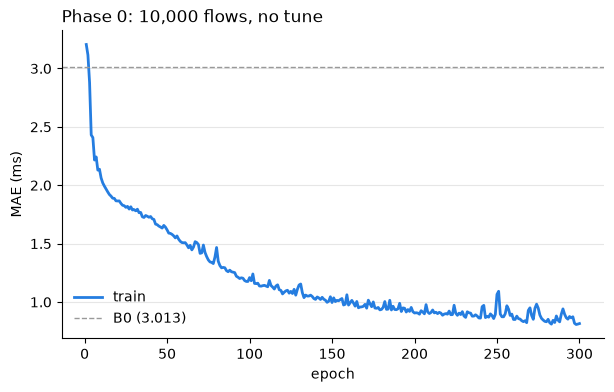

In [ ]:
plot_history(hist0b, title="Phase 0: 10,000 flows, no tune", reference=start)
plt.show()
#lr 1, 256

## 4. Fase 1: prima prova sui dati veri

Configurazione di riferimento (`BASE`): d = 16, strati 256 → 128, tabelle separate,
Adam lr = 1e-3, batch 4096, al massimo 20 epoche, early stopping sul tune (pazienza 3).

`run_trial(name, cfg)` addestra su `train_enc`, fa early stopping su `tune_enc` e scrive una
riga nel registro `results`, con i valori all'**epoca migliore**:
- MAE sul train (500.000 flow fissi) e sul tune;
- `gap` = tune − train: la distanza che useremo per riconoscere l'overfitting;
- numero di parametri e durata.

Le curve epoca per epoca restano in `histories`, per i grafici.

Riferimenti sul tune: B0 = 3,209. Per B2 e B4 si possono leggere i valori nelle tabelle
`results/tuning/.../b2.csv` e `b4.csv`, calcolati sullo stesso tune.

In [56]:
def run_trial(name, cfg):
    print(f"=== {name} ===")
    t0 = time.time()
    model, best_epoch, hist = fit_mlp(cfg, X_tr, x_tr, y_tr, X_tu, x_tu, y_tu, idx_check)
    best = hist.loc[hist["epoch"] == best_epoch].iloc[0]       # riga dell'epoca migliore
    results.append({
        "name": name, "d": cfg["d"], "hidden": str(cfg["hidden"]),
        "tables": "shared" if cfg["tables"] == SHARED else "separate",
        "lr": cfg["lr"], "schedule": cfg.get("schedule", "constant"),
        "epochs": cfg["max_epochs"], "norm": cfg.get("norm"),
        "dropout": cfg["dropout"], "seed": cfg["seed"],
        "best_epoch": best_epoch,
        "train_mae": best["train_mae"], "tune_mae": best["tune_mae"],
        "last_tune_mae": hist["tune_mae"].iloc[-1],            # ultima epoca
        "gap": best["tune_mae"] - best["train_mae"],
        "n_params": n_params(model),
        "minutes": round((time.time() - t0) / 60, 1),
    })
    histories[name] = hist
    return model

=== base ===
epoch = 1  train_mae = 1.9362  tune_mae = 1.7021  seconds = 9.3000
epoch = 2  train_mae = 1.9186  tune_mae = 1.6858  seconds = 8.3000
epoch = 3  train_mae = 1.9138  tune_mae = 1.6883  seconds = 8.4000
epoch = 4  train_mae = 1.9058  tune_mae = 1.6833  seconds = 8.6000
epoch = 5  train_mae = 1.9063  tune_mae = 1.6905  seconds = 8.1000
epoch = 6  train_mae = 1.9016  tune_mae = 1.6847  seconds = 8.0000
epoch = 7  train_mae = 1.8974  tune_mae = 1.6832  seconds = 8.0000
  early stopping: best epoch 4


,name,d,hidden,tables,lr,dropout,seed,best_epoch,train_mae,tune_mae,gap,n_params,minutes
0,base,16,"[256, 128]",separate,0.001,0.0,0,4,1.905822,1.6833,-0.222521,114481,1.0


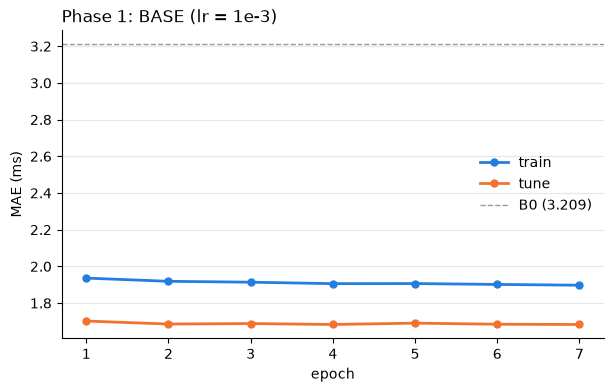

In [ ]:
results = []      # registro: una riga per prova
histories = {}    # curve epoca per epoca, per nome della prova

model = run_trial("base", BASE)

display(pd.DataFrame(results))
plot_history(histories["base"], title="Phase 1: BASE (lr = 1e-3)", reference=mae_b0_tune)
plt.show()

## 5. Riferimento: B2 sullo stesso tune

Per confrontare l'MLP alla pari, addestriamo B2 (stesse impostazioni finali: λ = 1e-5,
5 epoche, lr 0,01, gamma 0,5) su `train_enc` e misuriamo la MAE sugli stessi 500.000 flow del
train e sul tune. Serve a due cose:
- avere il valore di B2 sul tune, da battere;
- vedere se anche B2 ha un gap negativo: se sì, il gap negativo dipende dal periodo, non dal modello.

In [45]:
b2_model, _, _ = b2_linear.fit(X_tr, x_tr, y_tr, n_codes, lam=1e-5, epochs=5, lr=0.01,
                               gamma=0.5, batch=4096, seed=SEED, initial_intercept=median_tr)

b2_train = mae(b2_linear.predict(b2_model, X_tr[idx_check], x_tr[idx_check]), y_tr[idx_check])
b2_tune  = mae(b2_linear.predict(b2_model, X_tu, x_tu), y_tu)
print(f"B2: train MAE = {b2_train:.4f}, tune MAE = {b2_tune:.4f}, gap = {b2_tune - b2_train:+.4f}")

    epoch = 1 | lr = 0.01 | train_mae = 2.0788 | seconds = 1.7
    epoch = 2 | lr = 0.005 | train_mae = 1.9865 | seconds = 1.6
    epoch = 3 | lr = 0.0025 | train_mae = 1.9846 | seconds = 1.7
    epoch = 4 | lr = 0.00125 | train_mae = 1.984 | seconds = 1.6
    epoch = 5 | lr = 0.000625 | train_mae = 1.9838 | seconds = 1.6
B2: train MAE = 1.9884, tune MAE = 1.7629, gap = -0.2255


## 6. Fase 1: learning rate

Stessa configurazione `BASE`, cambia solo lr: 3e-4 e 3e-3 (oltre a 1e-3 già fatto).
Confronto sul tune MAE all'epoca migliore; colonna `vs_B2` = differenza dal riferimento
B2 sul tune (negativa = meglio di B2).
Regola decisa prima: se due lr differiscono di meno di ~0,005 li consideriamo pari
(il rumore tra seed lo misureremo dopo) e teniamo 1e-3.

=== lr_0.0003 ===
epoch = 1  train_mae = 1.9659  tune_mae = 1.7388  seconds = 8.5000
epoch = 2  train_mae = 1.9421  tune_mae = 1.7094  seconds = 8.7000
epoch = 3  train_mae = 1.9296  tune_mae = 1.6992  seconds = 7.7000
epoch = 4  train_mae = 1.9216  tune_mae = 1.6947  seconds = 8.0000
epoch = 5  train_mae = 1.9187  tune_mae = 1.6899  seconds = 7.1000
epoch = 6  train_mae = 1.9126  tune_mae = 1.6851  seconds = 7.3000
epoch = 7  train_mae = 1.9103  tune_mae = 1.6837  seconds = 7.0000
epoch = 8  train_mae = 1.9077  tune_mae = 1.6804  seconds = 6.9000
epoch = 9  train_mae = 1.9051  tune_mae = 1.6800  seconds = 6.6000
epoch = 10  train_mae = 1.9119  tune_mae = 1.6854  seconds = 8.3000
epoch = 11  train_mae = 1.9012  tune_mae = 1.6790  seconds = 7.8000
epoch = 12  train_mae = 1.9053  tune_mae = 1.6824  seconds = 7.3000
epoch = 13  train_mae = 1.9000  tune_mae = 1.6790  seconds = 7.4000
epoch = 14  train_mae = 1.8971  tune_mae = 1.6797  seconds = 7.4000
  early stopping: best epoch 11
=== lr_

,name,d,hidden,tables,lr,dropout,seed,best_epoch,train_mae,tune_mae,gap,n_params,minutes,vs_B2
0,base,16,"[256, 128]",separate,0.0010,0.0,0,4,1.905822,1.683300,-0.222521,114481,1.0,-0.079583
1,lr_0.0003,16,"[256, 128]",separate,0.0003,0.0,0,11,1.901188,1.678954,-0.222233,114481,1.8,-0.083929
2,lr_0.003,16,"[256, 128]",separate,0.0030,0.0,0,7,1.683337,1.567370,-0.115967,114481,1.3,-0.195513


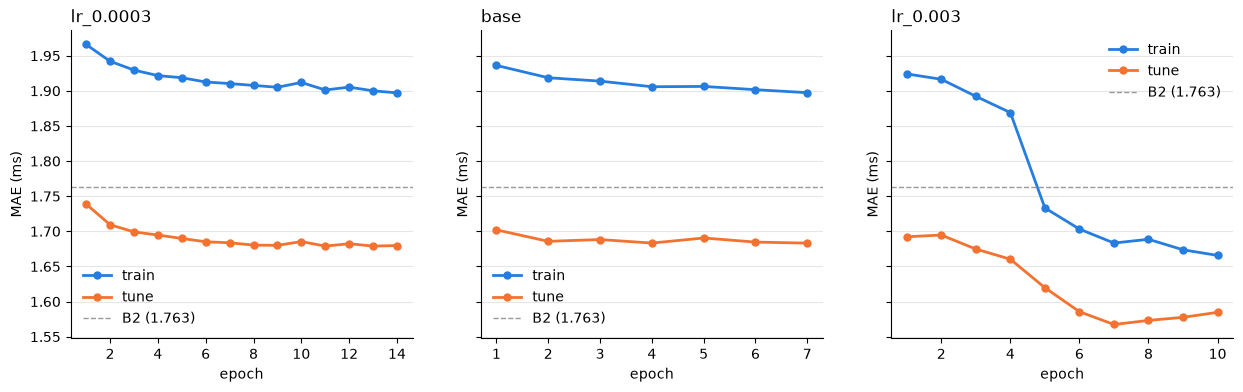

In [46]:
for lr in [3e-4, 3e-3]:
    run_trial(f"lr_{lr:g}", {**BASE, "lr": lr})

table = pd.DataFrame(results)
table["vs_B2"] = table["tune_mae"] - b2_tune
display(table)

names = ["lr_0.0003", "base", "lr_0.003"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, names):
    plot_history(histories[name], title=name, reference=b2_tune, ref_label="B2", ax=ax)
plt.show()

## 7. Fase 1: estensione della griglia e ripetibilità

lr = 3e-3 è il migliore ed è al bordo della griglia → proviamo anche 1e-2.
Il miglioramento di 3e-3 arriva con un salto improvviso (uscita da un plateau): ripetiamo
la prova con seed 1 e 2 per vedere se è ripetibile e quanto varia il tune MAE tra seed
(= il rumore sotto il quale due configurazioni sono da considerare pari).

=== lr_0.01 ===
epoch = 1  train_mae = 1.9269  tune_mae = 1.6922  seconds = 8.3000
epoch = 2  train_mae = 1.8026  tune_mae = 1.6583  seconds = 8.2000
epoch = 3  train_mae = 1.7244  tune_mae = 1.5912  seconds = 7.9000
epoch = 4  train_mae = 1.7066  tune_mae = 1.6211  seconds = 7.8000
epoch = 5  train_mae = 1.6995  tune_mae = 1.6056  seconds = 7.7000
epoch = 6  train_mae = 1.6811  tune_mae = 1.5903  seconds = 7.6000
epoch = 7  train_mae = 1.6809  tune_mae = 1.5978  seconds = 7.7000
epoch = 8  train_mae = 1.6920  tune_mae = 1.6358  seconds = 7.8000
epoch = 9  train_mae = 1.6898  tune_mae = 1.6034  seconds = 7.9000
  early stopping: best epoch 6
=== lr_0.003_seed1 ===
epoch = 1  train_mae = 1.9281  tune_mae = 1.7042  seconds = 8.2000
epoch = 2  train_mae = 1.9058  tune_mae = 1.6873  seconds = 8.2000
epoch = 3  train_mae = 1.8948  tune_mae = 1.6791  seconds = 8.2000
epoch = 4  train_mae = 1.7777  tune_mae = 1.6406  seconds = 8.3000
epoch = 5  train_mae = 1.7108  tune_mae = 1.6076  seconds =

,name,d,hidden,tables,lr,dropout,seed,best_epoch,train_mae,tune_mae,gap,n_params,minutes,vs_B2
0,base,16,"[256, 128]",separate,0.0010,0.0,0,4,1.905822,1.683300,-0.222521,114481,1.0,-0.079583
1,lr_0.0003,16,"[256, 128]",separate,0.0003,0.0,0,11,1.901188,1.678954,-0.222233,114481,1.8,-0.083929
2,lr_0.003,16,"[256, 128]",separate,0.0030,0.0,0,7,1.683337,1.567370,-0.115967,114481,1.3,-0.195513
3,lr_0.01,16,"[256, 128]",separate,0.0100,0.0,0,6,1.681125,1.590263,-0.090862,114481,1.2,-0.172620
4,lr_0.003_seed1,16,"[256, 128]",separate,0.0030,0.0,1,11,1.656552,1.557055,-0.099497,114481,1.9,-0.205828
5,lr_0.003_seed2,16,"[256, 128]",separate,0.0030,0.0,2,4,1.742151,1.643821,-0.098330,114481,1.0,-0.119062


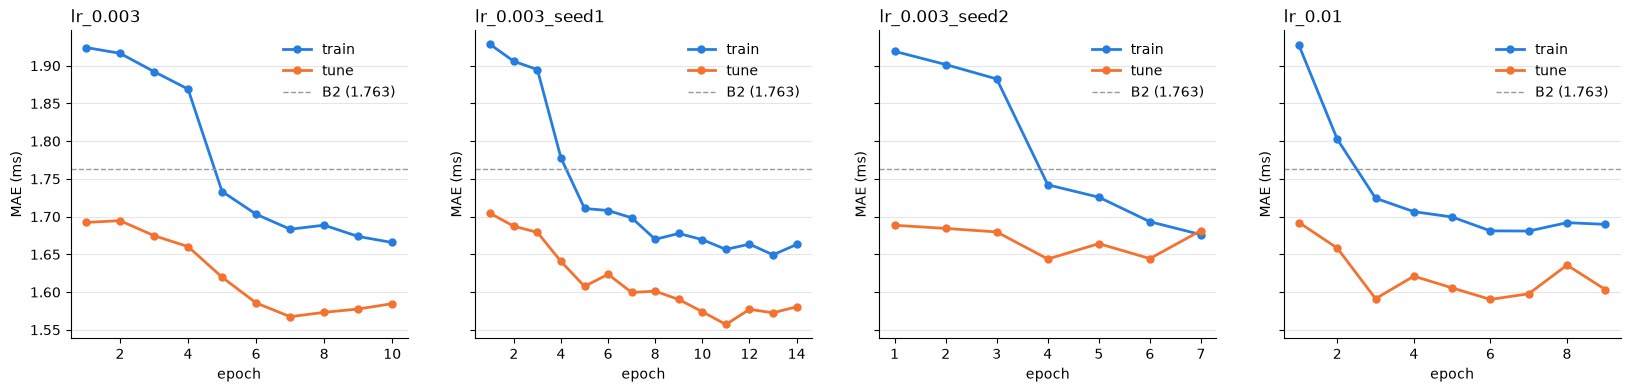

In [47]:
run_trial("lr_0.01", {**BASE, "lr": 1e-2})
for s in [1, 2]:
    run_trial(f"lr_0.003_seed{s}", {**BASE, "lr": 3e-3, "seed": s})

table = pd.DataFrame(results)
table["vs_B2"] = table["tune_mae"] - b2_tune
display(table)

names = ["lr_0.003", "lr_0.003_seed1", "lr_0.003_seed2", "lr_0.01"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, name in zip(axes, names):
    plot_history(histories[name], title=name, reference=b2_tune, ref_label="B2", ax=ax)
plt.show()

## 8. lr che cala a coseno

Con lr costante il tune MAE oscilla molto (fino a 0,09 tra seed): troppo rumore per confrontare
le architetture. Usiamo un lr che parte da 3e-3 e cala a coseno fino a ~0 in T = 15 epoche:
alto all'inizio per uscire dal plateau, basso alla fine per assestarsi.
Niente early stopping (pazienza = T): si fanno tutte le epoche.
Tre seed: se il tune MAE varia molto meno di prima, possiamo passare alla fase 2.

=== cos_seed0 ===
epoch  1  lr 3.0e-03  train 1.9241  tune 1.6922  (9.2 s)
epoch  2  lr 3.0e-03  train 1.9078  tune 1.6874  (8.0 s)
epoch  3  lr 2.9e-03  train 1.9081  tune 1.6870  (8.1 s)
epoch  4  lr 2.7e-03  train 1.8704  tune 1.6629  (7.9 s)
epoch  5  lr 2.5e-03  train 1.7653  tune 1.6362  (7.9 s)
epoch  6  lr 2.3e-03  train 1.7037  tune 1.6008  (7.8 s)
epoch  7  lr 2.0e-03  train 1.6843  tune 1.5648  (8.0 s)
epoch  8  lr 1.7e-03  train 1.6683  tune 1.5607  (7.8 s)
epoch  9  lr 1.3e-03  train 1.6670  tune 1.5681  (8.1 s)
epoch 10  lr 1.0e-03  train 1.6507  tune 1.5567  (8.1 s)
epoch 11  lr 7.5e-04  train 1.6485  tune 1.5591  (7.8 s)
epoch 12  lr 5.0e-04  train 1.6439  tune 1.5479  (8.0 s)
epoch 13  lr 2.9e-04  train 1.6364  tune 1.5548  (7.8 s)
epoch 14  lr 1.3e-04  train 1.6339  tune 1.5539  (7.9 s)
epoch 15  lr 3.3e-05  train 1.6332  tune 1.5528  (7.8 s)
=== cos_seed1 ===
epoch  1  lr 3.0e-03  train 1.9281  tune 1.7042  (8.4 s)
epoch  2  lr 3.0e-03  train 1.9043  tune 1.6852  (8.

,name,d,hidden,tables,lr,dropout,seed,best_epoch,train_mae,tune_mae,gap,n_params,minutes,vs_B2
0,base,16,"[256, 128]",separate,0.0010,0.0,0,4,1.905822,1.683300,-0.222521,114481,1.0,-0.079583
1,lr_0.0003,16,"[256, 128]",separate,0.0003,0.0,0,11,1.901188,1.678954,-0.222233,114481,1.8,-0.083929
2,lr_0.003,16,"[256, 128]",separate,0.0030,0.0,0,7,1.683337,1.567370,-0.115967,114481,1.3,-0.195513
3,lr_0.01,16,"[256, 128]",separate,0.0100,0.0,0,6,1.681125,1.590263,-0.090862,114481,1.2,-0.172620
4,lr_0.003_seed1,16,"[256, 128]",separate,0.0030,0.0,1,11,1.656552,1.557055,-0.099497,114481,1.9,-0.205828
5,lr_0.003_seed2,16,"[256, 128]",separate,0.0030,0.0,2,4,1.742151,1.643821,-0.098330,114481,1.0,-0.119062
6,cos_seed0,16,"[256, 128]",separate,0.0030,0.0,0,12,1.643909,1.547905,-0.096004,114481,2.0,-0.214978
7,cos_seed1,16,"[256, 128]",separate,0.0030,0.0,1,9,1.656668,1.574972,-0.081695,114481,2.0,-0.187911
8,cos_seed2,16,"[256, 128]",separate,0.0030,0.0,2,4,1.740415,1.622892,-0.117523,114481,1.9,-0.139991


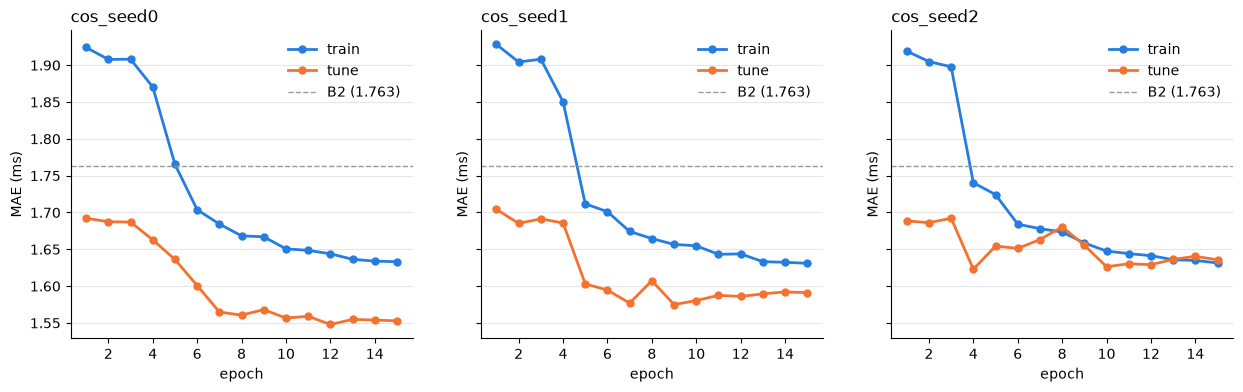

In [51]:
COS = {**BASE, "lr": 3e-3, "schedule": "cosine", "max_epochs": 15, "patience": 15}

for s in [0, 1, 2]:
    run_trial(f"cos_seed{s}", {**COS, "seed": s})

table = pd.DataFrame(results)
table["vs_B2"] = table["tune_mae"] - b2_tune
display(table)

names = ["cos_seed0", "cos_seed1", "cos_seed2"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, names):
    plot_history(histories[name], title=name, reference=b2_tune, ref_label="B2", ax=ax)
plt.show()

## 9. Batch normalization

Stessa configurazione `COS` (lr 3e-3 a coseno, 15 epoche), con batch norm dopo ogni strato
nascosto: Linear → BatchNorm → ReLU. Ogni neurone viene normalizzato sul batch e poi
riscalato con due parametri imparati, γ (scala) e β (spostamento).
Tre seed, come per `COS`. Confronto tra i due gruppi:
- media del tune MAE (quale va meglio);
- deviazione standard tra seed (quale è più stabile).

=== cos_bn_seed0 ===
epoch  1  lr 3.0e-03  train 1.9291  tune 1.7003  (10.5 s)
epoch  2  lr 3.0e-03  train 1.9046  tune 1.6785  (9.2 s)
epoch  3  lr 2.9e-03  train 1.8942  tune 1.6763  (8.9 s)
epoch  4  lr 2.7e-03  train 1.8888  tune 1.6748  (9.0 s)
epoch  5  lr 2.5e-03  train 1.8794  tune 1.6700  (8.9 s)
epoch  6  lr 2.3e-03  train 1.8825  tune 1.6811  (9.2 s)
epoch  7  lr 2.0e-03  train 1.8603  tune 1.6738  (9.4 s)
epoch  8  lr 1.7e-03  train 1.8645  tune 1.6939  (9.3 s)
epoch  9  lr 1.3e-03  train 1.8450  tune 1.6790  (8.8 s)
epoch 10  lr 1.0e-03  train 1.8333  tune 1.7008  (8.7 s)
epoch 11  lr 7.5e-04  train 1.8283  tune 1.7195  (8.7 s)
epoch 12  lr 5.0e-04  train 1.8339  tune 1.7580  (8.8 s)
epoch 13  lr 2.9e-04  train 1.8437  tune 1.7772  (8.6 s)
epoch 14  lr 1.3e-04  train 1.8114  tune 1.7488  (9.0 s)
epoch 15  lr 3.3e-05  train 1.8102  tune 1.7444  (8.8 s)
=== cos_bn_seed1 ===
epoch  1  lr 3.0e-03  train 1.9248  tune 1.6950  (8.9 s)
epoch  2  lr 3.0e-03  train 1.9048  tune 1.67

tune_mae           last_tune_mae                 gap          
            mean       std          mean       std      mean       std
group                                                                 
cos     1.581923  0.037973      1.593246  0.041482 -0.098408  0.018034
cos_bn  1.633882  0.031291      1.661905  0.071473 -0.091377  0.103012

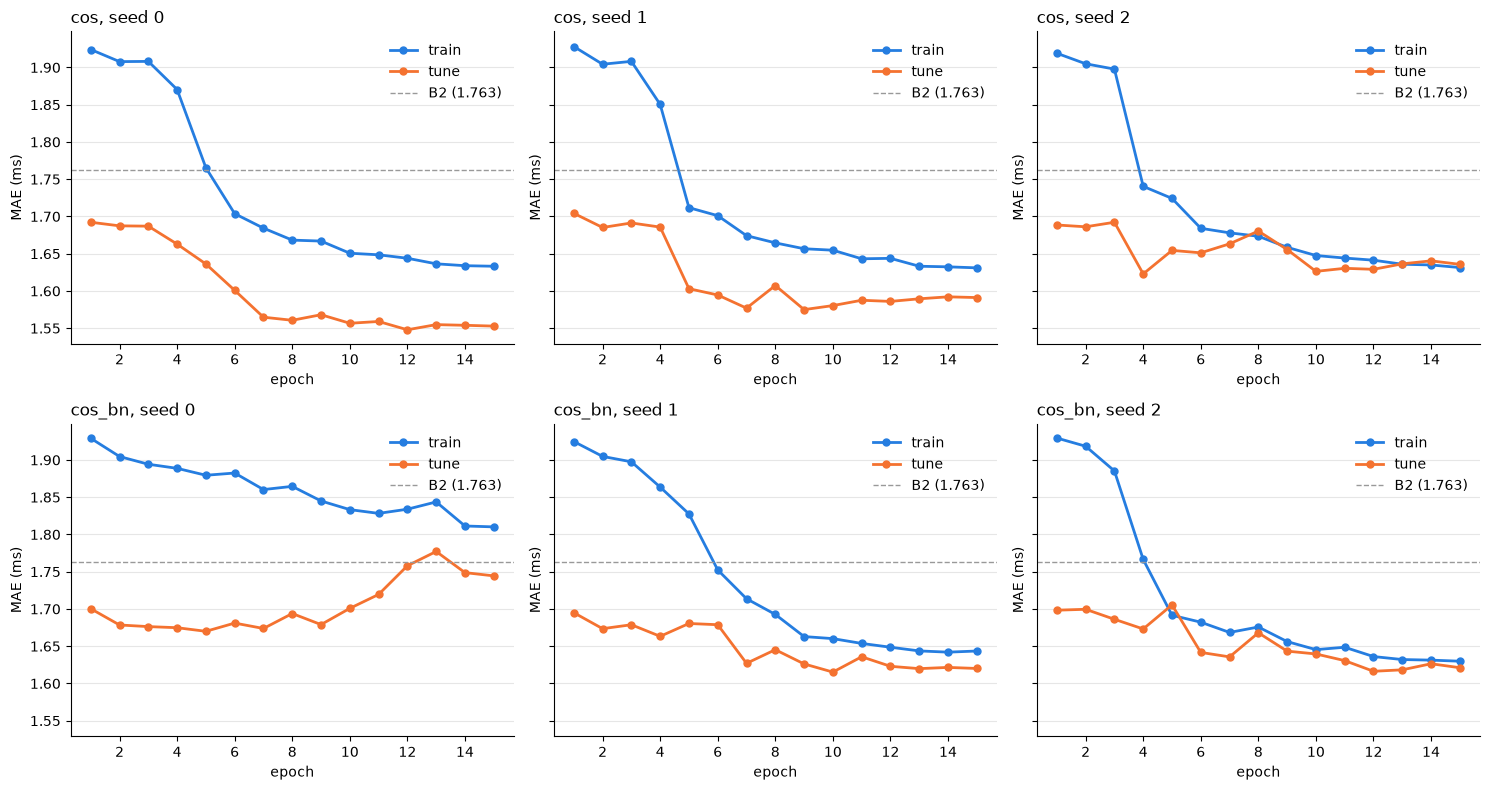

layer 1: gamma mean 0.635 (min 0.259, max 1.396), beta mean -0.475
layer 4: gamma mean 0.868 (min 0.408, max 3.589), beta mean -0.169


In [59]:
COS_BN = {**COS, "norm": "batch"}
for s in [0, 1, 2]:
    model_bn = run_trial(f"cos_bn_seed{s}", {**COS_BN, "seed": s})

table = pd.DataFrame(results)
table["vs_B2"] = table["tune_mae"] - b2_tune
table["group"] = table["name"].str.replace(r"_seed\d+$", "", regex=True)

cos_rows = table[table["group"].isin(["cos", "cos_bn"])]
display(cos_rows.groupby("group")[["tune_mae", "last_tune_mae", "gap"]].agg(["mean", "std"]))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for r, group in enumerate(["cos", "cos_bn"]):
    for s in range(3):
        plot_history(histories[f"{group}_seed{s}"], title=f"{group}, seed {s}",
                     reference=b2_tune, ref_label="B2", ax=axes[r, s])
plt.tight_layout()
plt.show()

# cosa hanno imparato gamma e beta (ultimo modello addestrato)
for i, layer in enumerate(model_bn.body):
    if isinstance(layer, nn.BatchNorm1d):
        g, b = layer.weight.detach(), layer.bias.detach()
        print(f"layer {i}: gamma mean {g.mean():.3f} (min {g.min():.3f}, max {g.max():.3f}), "
              f"beta mean {b.mean():.3f}")

In [57]:
import inspect
print("MLP has norm:      ", "norm" in inspect.signature(MLP).parameters)
print("fit_mlp passes norm:", 'cfg.get("norm")' in inspect.getsource(fit_mlp))
print("run_trial new fields:", "last_tune_mae" in inspect.getsource(run_trial))
print(MLP(n_codes, 16, [256, 128], median_tr, SEPARATE, norm="batch").body)

MLP has norm:       True
fit_mlp passes norm: True
run_trial new fields: True
Sequential(
  (0): Linear(in_features=209, out_features=256, bias=False)
  (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=False)
  (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
)


In [58]:
# togli le prove cos_bn sbagliate (fatte senza batch norm)
results = [r for r in results if not r["name"].startswith("cos_bn")]
for name in [n for n in histories if n.startswith("cos_bn")]:
    del histories[name]

# aggiungi alle prove vecchie i campi nuovi, ricavandoli dalle curve salvate
for r in results:
    is_cos = r["name"].startswith("cos")
    r.setdefault("last_tune_mae", histories[r["name"]]["tune_mae"].iloc[-1])
    r.setdefault("schedule", "cosine" if is_cos else "constant")
    r.setdefault("epochs", 15 if is_cos else 20)
    r.setdefault("norm", None)

display(pd.DataFrame(results)[["name", "lr", "schedule", "norm", "seed",
                               "tune_mae", "last_tune_mae", "gap"]])

,name,lr,schedule,norm,seed,tune_mae,last_tune_mae,gap
0,base,0.0010,constant,None,0,1.683300,1.683210,-0.222521
1,lr_0.0003,0.0003,constant,None,0,1.678954,1.679747,-0.222233
2,lr_0.003,0.0030,constant,None,0,1.567370,1.584677,-0.115967
3,lr_0.01,0.0100,constant,None,0,1.590263,1.603407,-0.090862
4,lr_0.003_seed1,0.0030,constant,None,1,1.557055,1.580526,-0.099497
5,lr_0.003_seed2,0.0030,constant,None,2,1.643821,1.681564,-0.098330
6,cos_seed0,0.0030,cosine,None,0,1.547905,1.552849,-0.096004
7,cos_seed1,0.0030,cosine,None,1,1.574972,1.591154,-0.081695
8,cos_seed2,0.0030,cosine,None,2,1.622892,1.635734,-0.117523


## 10. Diagnosi: dove i seed non sono d'accordo

Ipotesi: con loss L1 e target bimodale (0 e ~5 ms), per i gruppi di flow con un mix bilanciato
dei due regimi qualunque previsione tra 0 e 5 dà lo stesso errore sul train. Seed diversi
scelgono valori diversi, che sul tune (con un mix un po' diverso) danno errori diversi.

Se è vera, i tre modelli `COS` dovrebbero essere in disaccordo soprattutto sui flow con previsione
**intermedia** (tra 1 e 4 ms) e molto meno sui flow previsti vicino a 0 o a 5.
Misuriamo anche la MAE della media delle tre previsioni (ensemble).

In [61]:
# riaddestra i 3 modelli COS senza tune: si tiene l'ultima epoca (stessi modelli di prima)
models_cos = {}
for s in [0, 1, 2]:
    print(f"--- seed {s} ---")
    models_cos[s], _, _ = fit_mlp({**COS, "seed": s, "print_every": 5}, X_tr, x_tr, y_tr)

preds = np.stack([predict(models_cos[s], X_tu, x_tu) for s in range(3)])   # (3, n_tune)
for s in range(3):
    print(f"seed {s}: tune MAE = {mae(preds[s], y_tu):.4f}")
print(f"ensemble (mean of 3): tune MAE = {mae(preds.mean(axis=0), y_tu):.4f}")

# disaccordo per flow: distanza tra la previsione più alta e la più bassa
spread = preds.max(axis=0) - preds.min(axis=0)
mean_pred = preds.mean(axis=0)
bins = pd.cut(mean_pred, [-np.inf, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, np.inf])
display(pd.DataFrame({"mean prediction": bins, "spread": spread})
        .groupby("mean prediction", observed=True)["spread"]
        .agg(n_flows="count", mean_spread="mean", median_spread="median"))

--- seed 0 ---
epoch  5  lr 2.5e-03  train 1.7599  (10.9 s)
epoch 10  lr 1.0e-03  train 1.6409  (10.3 s)
epoch 15  lr 3.3e-05  train 1.6239  (8.5 s)
--- seed 1 ---
epoch  5  lr 2.5e-03  train 1.7009  (8.4 s)
epoch 10  lr 1.0e-03  train 1.6442  (7.6 s)
epoch 15  lr 3.3e-05  train 1.6215  (8.9 s)
--- seed 2 ---
epoch  5  lr 2.5e-03  train 1.7167  (8.7 s)
epoch 10  lr 1.0e-03  train 1.6367  (8.4 s)
epoch 15  lr 3.3e-05  train 1.6202  (8.2 s)
seed 0: tune MAE = 1.5528
seed 1: tune MAE = 1.5912
seed 2: tune MAE = 1.6357
ensemble (mean of 3): tune MAE = 1.5844


,n_flows,mean_spread,median_spread
mean prediction,,,
"(-inf, 0.5]",340544,0.616102,0.022136
"(0.5, 1.5]",47797,0.296734,0.118275
"(1.5, 2.5]",25529,0.569472,0.264795
"(2.5, 3.5]",21659,0.945103,0.649863
"(3.5, 4.5]",40152,0.407668,0.216769
"(4.5, 5.5]",497390,0.068194,0.035118
"(5.5, inf]",27280,0.226668,0.108085


## 11. Inizializzazione He

Pesi degli strati nascosti ~ N(0, 2/n_in) invece del default di PyTorch (uniforme, varianza
1/(3·n_in), 6 volte più piccola): conserva la scala del segnale attraverso le ReLU.
Stessa configurazione `COS`, 3 seed. Confronto con `cos` su:
- media e std di `last_tune_mae`;
- epoca di uscita dal plateau (prima epoca con MAE sul train < 1,80).

In [ ]:
COS_HE = {**COS, "init": "he"}
for s in [0, 1, 2]:
    run_trial(f"cos_he_seed{s}", {**COS_HE, "seed": s})

def exit_epoch(hist, threshold=1.80):
    below = hist.loc[hist["train_mae"] < threshold, "epoch"]
    return int(below.iloc[0]) if len(below) else None

table = pd.DataFrame(results)
table["group"] = table["name"].str.replace(r"_seed\d+$", "", regex=True)
table["exit_epoch"] = [exit_epoch(histories[n]) for n in table["name"]]

rows = table[table["group"].isin(["cos", "cos_he"])]
display(rows[["name", "last_tune_mae", "gap", "exit_epoch"]])
display(rows.groupby("group")[["last_tune_mae", "exit_epoch"]].agg(["mean", "std"]))

=== cos_he_seed0 ===
epoch  1  lr 3.0e-03  train 1.9145  tune 1.6921  (9.3 s)
epoch  2  lr 3.0e-03  train 1.8899  tune 1.6773  (8.9 s)
